# ⚙️ Notebook 02 : Prototypage de Pipeline, Modélisation et Optimisation
## Projet : Student Performance Prediction
### Objectif :
1. Mettre en place un pipeline Scikit-Learn étanche (aucun *data leakage*).
2. Valider et comparer 5 algorithmes sous validation croisée stratifiée ($k=5$).
3. Évaluer les performances sur jeu de test indépendant (ROC-AUC, Confusion Matrix, F1-Score).
4. Optimiser les hyperparamètres via `GridSearchCV`.
5. Interpréter l'importance des variables (*Permutation Importance*).

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_raw_data, prepare_features_and_target, split_data
from src.preprocessing import create_preprocessor, identify_column_types
from src.models import get_default_models, get_hyperparameter_grids, build_pipeline
from src.evaluate import benchmark_all_models, tune_best_model, analyze_feature_importance
from src.utils import set_plot_style

set_plot_style()
print("Modules du projet importés avec succès.")

Modules du projet importés avec succès.


## 1. Chargement et découpage Train / Test sans fuite d'information
Pour évaluer l'impact socio-démographique pur, nous excluons les notes intermédiaires `G1` et `G2`.

In [2]:
df = load_raw_data("../data/raw/student-mat.csv")
X, y = prepare_features_and_target(df, target_type="binary", include_intermediate_grades=False)

X_train, X_test, y_train, y_test = split_data(X, y, test_size=0.2, random_state=42, stratify=True)
num_cols, cat_cols = identify_column_types(X_train)

print(f"Échantillon Train : {X_train.shape[0]} étudiants")
print(f"Échantillon Test  : {X_test.shape[0]} étudiants")
print(f"Variables numériques   : {len(num_cols)}")
print(f"Variables catégorielles : {len(cat_cols)}")

2026-10-06 19:28:06,878 - INFO - Données brutes chargées : 395 lignes, 33 colonnes.


2026-10-06 19:28:06,881 - INFO - Partitionnement Train/Test terminé (test_size=0.2) :
  - X_train : (316, 30), y_train : (316,)
  - X_test  : (79, 30), y_test  : (79,)


Échantillon Train : 316 étudiants
Échantillon Test  : 79 étudiants
Variables numériques   : 13
Variables catégorielles : 17


## 2. Construction du ColumnTransformer Scikit-Learn
- **Variables numériques** : Imputation médiane + `StandardScaler`
- **Variables catégorielles** : Imputation mode + `OneHotEncoder(handle_unknown='ignore')`

In [3]:
preprocessor = create_preprocessor(num_cols, cat_cols)
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'Medu', 'Fedu', 'traveltime',
                                  'studytime', 'failures', 'famrel', 'freetime',
                                  'goout', 'Dalc', 'Walc', 'health',
                                  'absences']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['school', 'sex', 'address', 'famsize',
                                  'Pstatus', 'Mjob', 'Fjob', 'reason',
                                  'guardian', 'schoolsup', 'famsup', 'paid',
                                  'activities', 'nursery', 'higher', 'internet',
                                  'romantic'])])

## 3. Comparaison systématique des modèles (Stratified K-Fold k=5)
Algorithmes testés :
1. **Logistic Regression** (baseline linéaire pondérée)
2. **K-Nearest Neighbors** (approche par proximité)
3. **Decision Tree Classifier** (arbre cartographique)
4. **Random Forest Classifier** (forêt aléatoire d'arbres)
5. **Gradient Boosting Classifier** (ensemble séquentiel avec boosting)

2026-10-06 19:28:06,896 - INFO - Démarrage du benchmark comparatif sur 5 algorithmes...


2026-10-06 19:28:06,896 - INFO - --- Évaluation de : Logistic Regression ---


2026-10-06 19:28:08,806 - INFO - --- Évaluation de : K-Nearest Neighbors ---


2026-10-06 19:28:10,056 - INFO - --- Évaluation de : Decision Tree ---


2026-10-06 19:28:10,273 - INFO - --- Évaluation de : Random Forest ---


2026-10-06 19:28:10,762 - INFO - --- Évaluation de : Gradient Boosting ---


2026-10-06 19:28:11,538 - INFO - Modèle le plus performant identifié : Random Forest


,model,cv_accuracy_mean,cv_f1_weighted_mean,test_accuracy,test_f1_weighted,test_roc_auc
3,Random Forest,0.683681,0.651551,0.683544,0.655969,0.638607
2,Decision Tree,0.601587,0.600318,0.607595,0.618338,0.629898
0,Logistic Regression,0.683780,0.687561,0.594937,0.601461,0.595065
4,Gradient Boosting,0.677381,0.658889,0.582278,0.569467,0.496372
1,K-Nearest Neighbors,0.683581,0.643291,0.582278,0.554909,0.522134


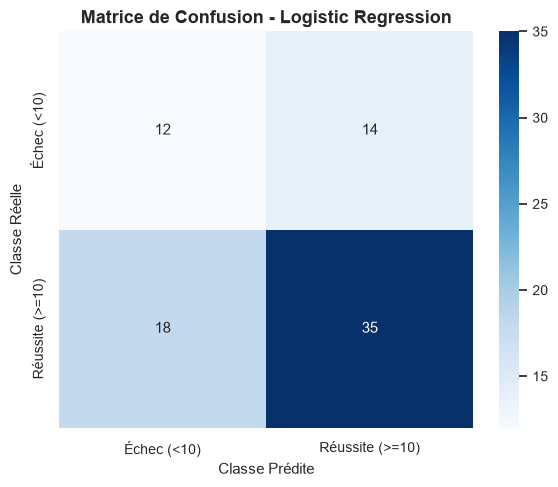

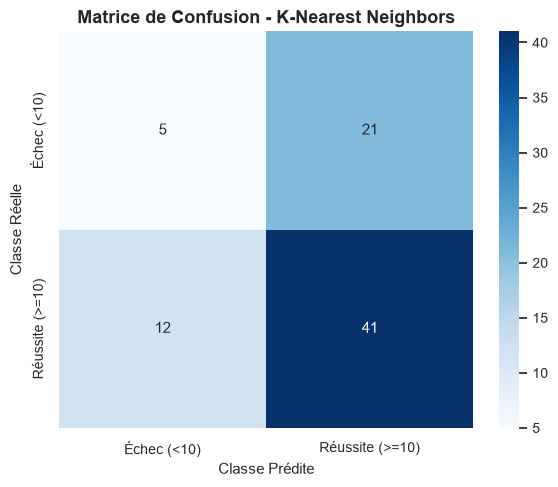

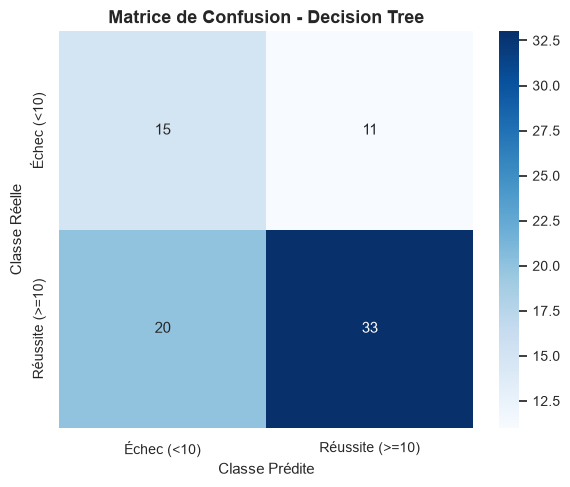

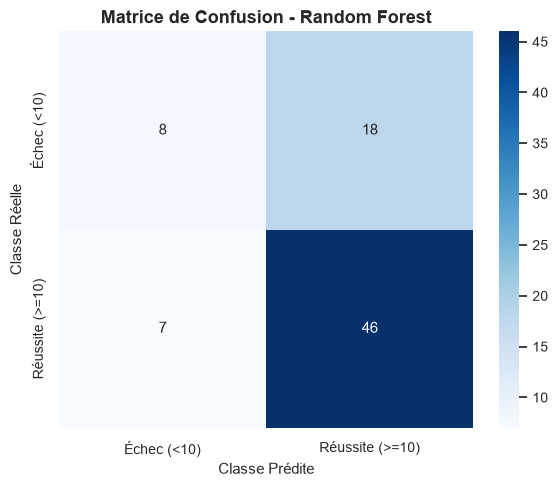

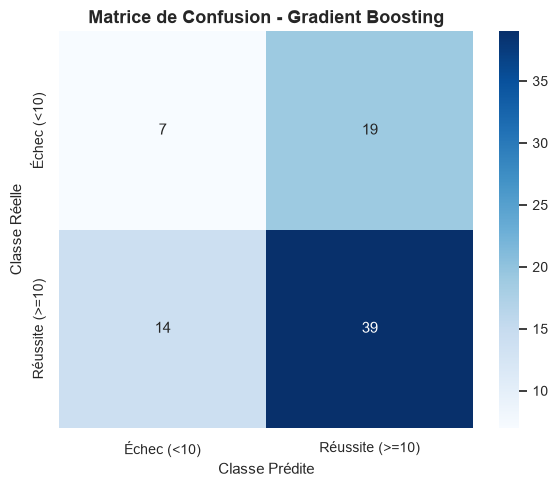

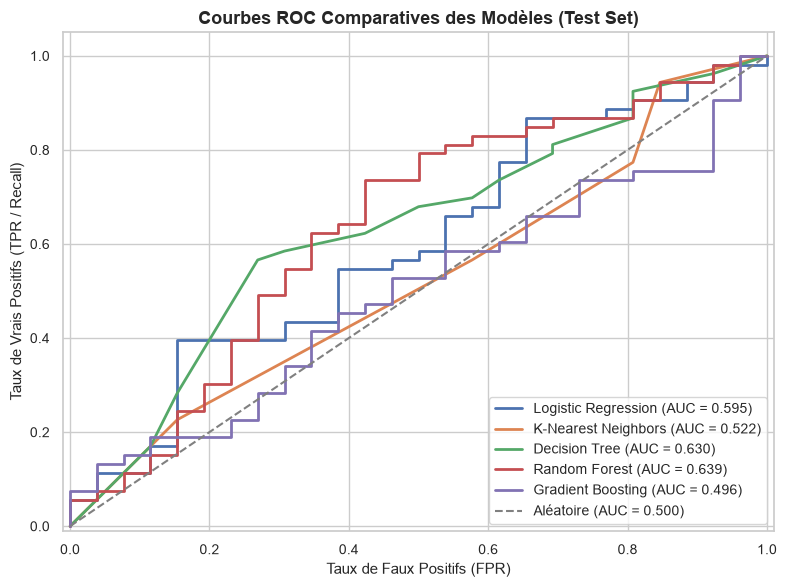

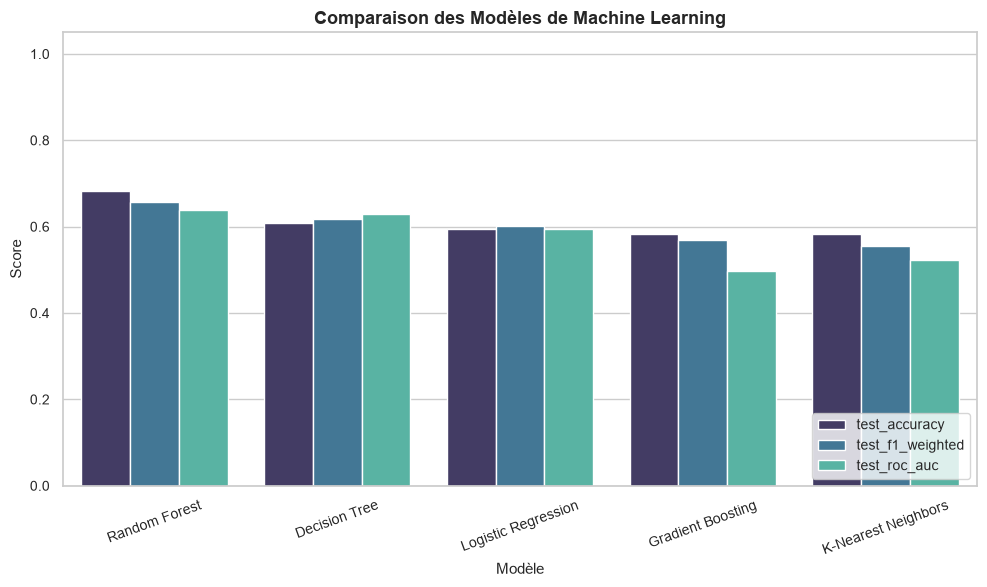

In [4]:
benchmark_df, fitted_pipelines, best_name = benchmark_all_models(
    X_train, y_train, X_test, y_test, num_cols, cat_cols, output_dir="../reports"
)

display_cols = [
    "model", "cv_accuracy_mean", "cv_f1_weighted_mean", 
    "test_accuracy", "test_f1_weighted", "test_roc_auc"
]
benchmark_df[display_cols]

## 4. Visualisation comparative des performances

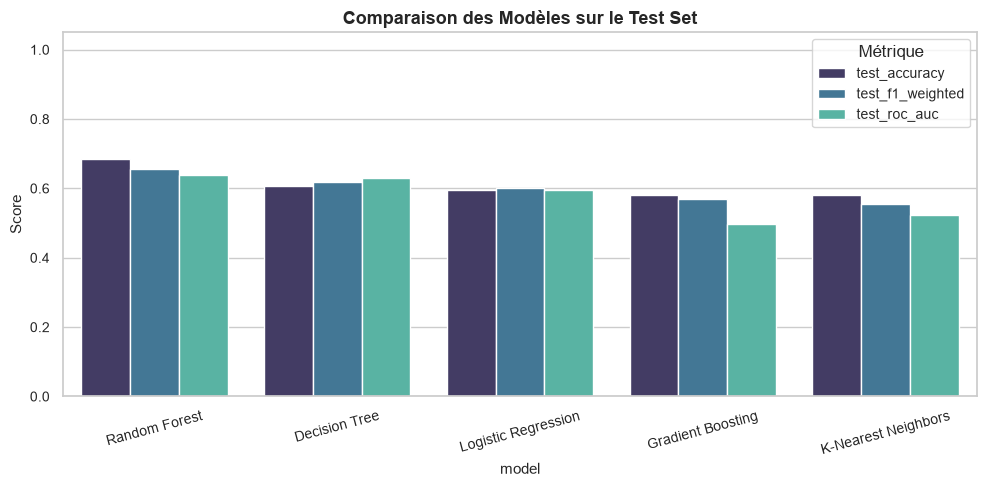

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
melted = pd.melt(
    benchmark_df, 
    id_vars=['model'], 
    value_vars=['test_accuracy', 'test_f1_weighted', 'test_roc_auc'], 
    var_name='Métrique', 
    value_name='Score'
)
sns.barplot(data=melted, x='model', y='Score', hue='Métrique', ax=ax, palette='mako')
ax.set_ylim([0, 1.05])
ax.set_title("Comparaison des Modèles sur le Test Set")
plt.xticks(rotation=15)
plt.show()

## 5. Optimisation fine des hyperparamètres (GridSearchCV) sur le meilleur modèle

2026-10-06 19:28:12,252 - INFO - Démarrage de l'optimisation GridSearchCV pour Random Forest...


Fitting 5 folds for each of 324 candidates, totalling 1620 fits


2026-10-06 19:29:15,127 - INFO - Modèle optimisé sauvegardé dans models/best_model.joblib


Meilleurs hyperparamètres trouvés :
{'classifier__max_depth': 12, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Score F1-Weighted en validation croisée : 0.7194
Score F1-Weighted sur Test Set           : 0.6358
ROC-AUC sur Test Set                     : 0.6386


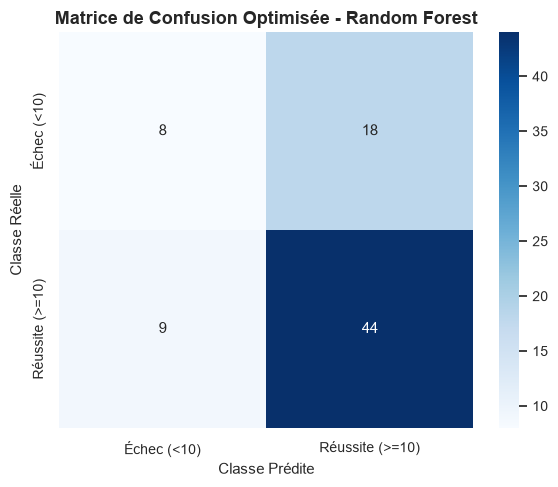

In [6]:
best_pipe, tuning_report = tune_best_model(
    best_name, X_train, y_train, X_test, y_test, num_cols, cat_cols, cv_folds=5
)

print(f"Meilleurs hyperparamètres trouvés :\n{tuning_report['best_params']}")
print(f"Score F1-Weighted en validation croisée : {tuning_report['best_cv_f1_weighted']:.4f}")
print(f"Score F1-Weighted sur Test Set           : {tuning_report['test_metrics']['test_f1_weighted']:.4f}")
print(f"ROC-AUC sur Test Set                     : {tuning_report['test_metrics']['test_roc_auc']:.4f}")

## 6. Analyse d'importance des variables (Permutation Importance)

2026-10-06 19:29:15,207 - INFO - Calcul de l'importance des variables...


,feature,importance_mean,importance_std
14,failures,0.025040,0.036136
17,paid,0.015464,0.005155
13,studytime,0.012766,0.007010
25,goout,0.008849,0.006129
16,famsup,0.008641,0.011414
1,sex,0.008461,0.006160
24,freetime,0.008436,0.008457
15,schoolsup,0.007128,0.012426
23,famrel,0.006160,0.007793
26,Dalc,0.001768,0.009151


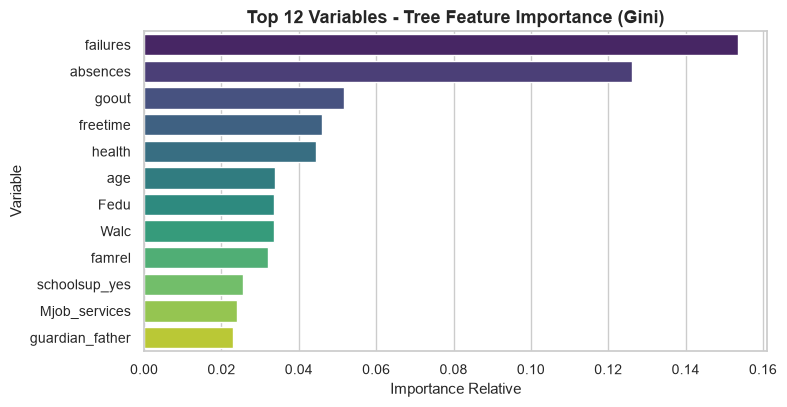

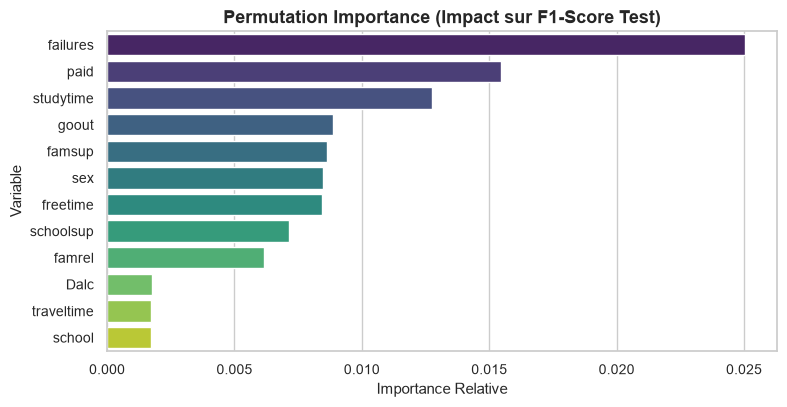

In [7]:
perm_df = analyze_feature_importance(best_pipe, X_train, X_test, y_test, top_n=12)
perm_df.head(12)

## 7. Conclusions et Perspectives
- Le modèle optimisé et les graphiques d'évaluation sont sauvegardés dans les dossiers `models/` et `reports/figures/`.
- La démarche garantit l'absence de fuite de données et respecte les critères d'ingénierie logicielle pour un déploiement fiable.